# COU 07506 – Week 4 – z-Transform Laboratory: Poles, Zeros and Stability
**Name:** Iddy Omary
**Registration number:** 240242439347
**Date:** 26 November 2026
**Group:** BEng24COE-2
**Git repository:** https://github.com/iddyiom/COU07506-labs

## Pre-lab
**(a)** H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²) → z² − 0.9z + 0.81 = 0 → z = 0.45 ± j0.7794 = 0.9·e^{±jπ/3}.
|p| = 0.9 < 1, so the causal system is **stable**.

**(b)** X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)] = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹)
A = 1/(1 − 0.25/0.5) = **2**, B = 1/(1 − 0.5/0.25) = **−1**
so X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹) and x(n) = 2(0.5)ⁿ − (0.25)ⁿ.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 4.1 – A pole-zero plotting function

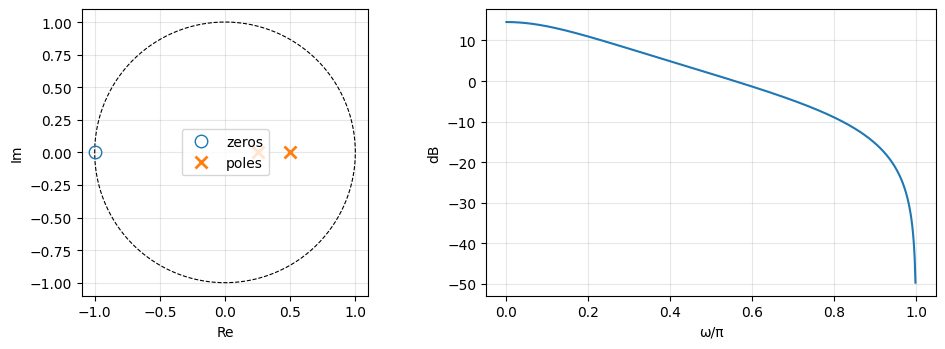

poles: [0.5  0.25]  stable: True


In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.grid(alpha=0.3)
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H))); ax2.set_xlabel("ω/π"); ax2.set_ylabel("dB")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

**Observation (4.1):** zero at z = −1 (gives a null at ω = π), poles at z = 0.5 and 0.25 (both inside the unit circle) → stable. The response is a low-pass shape with a deep null at ω/π = 1.

## Task 4.2 – Inverse z-transform with residuez

In [3]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print(np.allclose(x_pf, x_lf))

# system of Task 4.1, b = [1, 1]
r2, p2, k2 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("\nb=[1,1]: residues", r2, "poles", p2)
h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
h_formula = 6*0.5**n - 5*0.25**n
print("residuez == lfilter:", np.allclose(h_pf, h_lf))
print("h(n) = 6(0.5)^n - 5(0.25)^n :", np.allclose(h_formula, h_lf))

residues [-1.  2.] poles [0.25 0.5 ]
True

b=[1,1]: residues [-5.  6.] poles [0.25 0.5 ]
residuez == lfilter: True
h(n) = 6(0.5)^n - 5(0.25)^n : True


**Observation (4.2):** residuez gives residues 2 and −1 for poles 0.5 and 0.25, matching my pre-lab answer (b) (the pre-lab X(z) has the same denominator). For b = [1, 1] the residues are 6 and −5, so h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, confirmed against lfilter.

## Task 4.3 – Pole position and the impulse response

r =  0.5: peak |H| =      1.89   max|h| over n=32..39:    0.0000   stable: True
r =  0.8: peak |H| =      3.93   max|h| over n=32..39:    0.0009   stable: True
r = 0.95: peak |H| =     14.50   max|h| over n=32..39:    0.2603   stable: True
r =  1.0: peak |H| = 4422699262794037.00   max|h| over n=32..39:    1.4142   stable: False
r = 1.05: peak |H| =     13.79   max|h| over n=32..39:    8.6004   stable: False


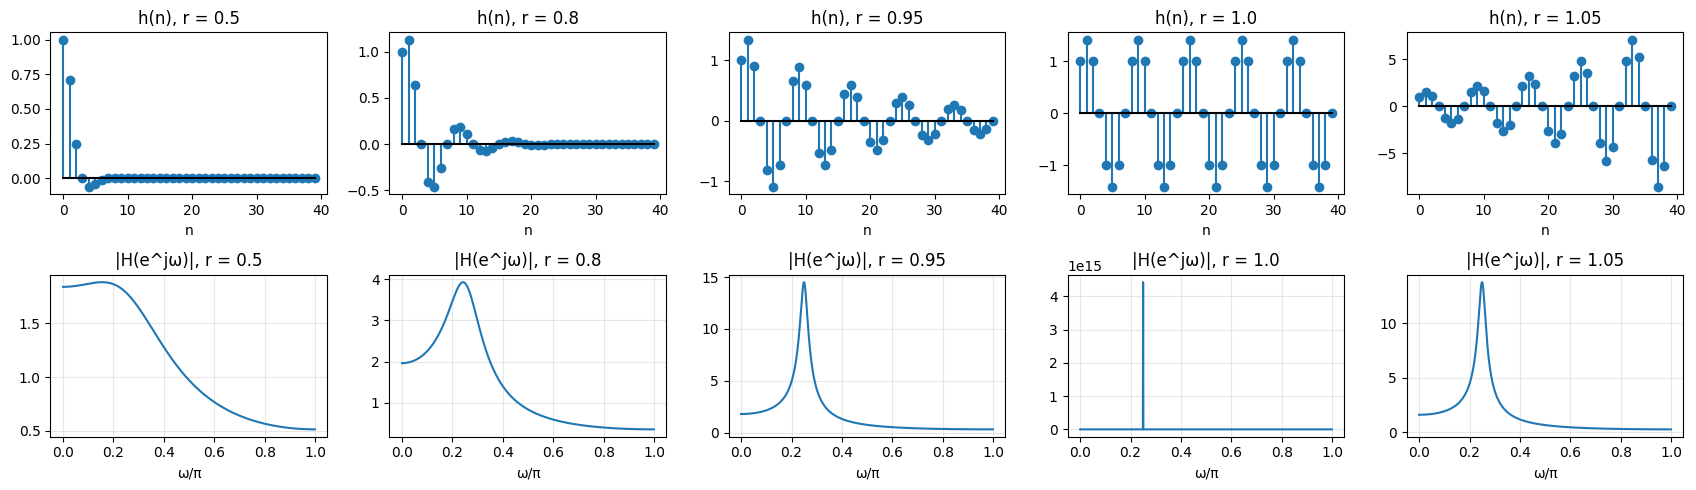

In [4]:
theta = np.pi/4
n = np.arange(40)
imp = np.zeros(40); imp[0] = 1
rs = [0.5, 0.8, 0.95, 1.0, 1.05]
fig, axes = plt.subplots(2, 5, figsize=(17, 5))
for i, r in enumerate(rs):
    a = [1, -2*r*np.cos(theta), r**2]
    h = signal.lfilter([1], a, imp)
    w, H = signal.freqz([1], a, worN=1024)
    axes[0, i].stem(n, h, basefmt="k-"); axes[0, i].set_title(f"h(n), r = {r}")
    axes[0, i].set_xlabel("n")
    axes[1, i].plot(w/np.pi, np.abs(H)); axes[1, i].set_title(f"|H(e^jω)|, r = {r}")
    axes[1, i].set_xlabel("ω/π"); axes[1, i].grid(alpha=0.3)
    print(f"r = {r:4}: peak |H| = {np.abs(H).max():9.2f}   max|h| over n=32..39: {np.abs(h[-8:]).max():9.4f}   stable: {r < 1}")
plt.tight_layout(); plt.show()

**Observation (4.3):** h(n) = rⁿ·sin((n+1)π/4)/sin(π/4), a sinusoid of period 8 samples under an envelope rⁿ.
- r = 0.5, 0.8: decays quickly, broad low peak at ω = π/4.
- r = 0.95: decays slowly (many visible oscillations); the peak is tall and narrow.
- r = 1.0: oscillation neither decays nor grows (constant amplitude); the peak is infinite.
- r = 1.05: oscillation grows exponentially.

**Unstable:** r = 1.05 (|p| > 1). r = 1.0 is marginally stable (bounded but not decaying, not BIBO stable). Stable: r = 0.5, 0.8, 0.95.

## Task 4.4 – Stability of given systems

(a) 1/(1-1.6z^-1+0.89z^-2)       poles = [0.8+0.5j 0.8-0.5j]  max|p| = 0.9434  -> STABLE;  max|h| first 20 = 1.67, last 20 = 0.172
(b) (1+z^-1)/(1-2.5z^-1+z^-2)    poles = [2.  0.5]  max|p| = 2.0000  -> UNSTABLE;  max|h| first 20 = 1.05e+06, last 20 = 1.15e+18
(c) 1/(1+0.5z^-1-0.5z^-2)        poles = [-1.   0.5]  max|p| = 1.0000  -> MARGINAL (|p|=1);  max|h| first 20 = 1, last 20 = 0.667
(d) 1 - z^-4                     poles = []  max|p| = 0.0000  -> STABLE;  max|h| first 20 = 1, last 20 = 0


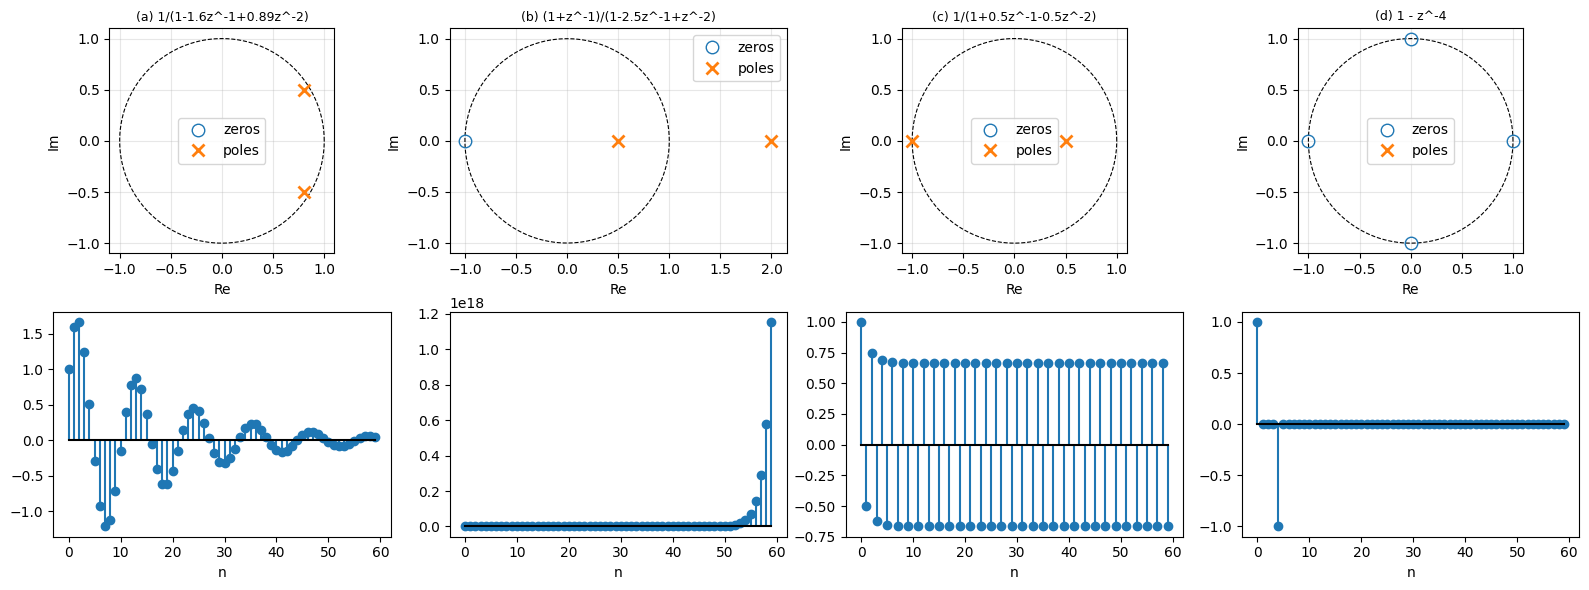

In [5]:
systems = {
    "(a) 1/(1-1.6z^-1+0.89z^-2)":  ([1],        [1, -1.6, 0.89]),
    "(b) (1+z^-1)/(1-2.5z^-1+z^-2)": ([1, 1],   [1, -2.5, 1]),
    "(c) 1/(1+0.5z^-1-0.5z^-2)":   ([1],        [1, 0.5, -0.5]),
    "(d) 1 - z^-4":                ([1, 0, 0, 0, -1], [1]),
}
imp = np.zeros(60); imp[0] = 1
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[0, i]); axes[0, i].set_title(name, fontsize=9)
    h = signal.lfilter(b, a, imp)
    axes[1, i].stem(np.arange(60), h, basefmt="k-"); axes[1, i].set_xlabel("n")
    pm = np.max(np.abs(p)) if len(p) else 0
    verdict = "STABLE" if pm < 1 - 1e-9 else ("MARGINAL (|p|=1)" if abs(pm-1) < 1e-9 else "UNSTABLE")
    print(f"{name:32s} poles = {np.round(p, 4)}  max|p| = {pm:.4f}  -> {verdict};  "
          f"max|h| first 20 = {np.abs(h[:20]).max():.3g}, last 20 = {np.abs(h[-20:]).max():.3g}")
plt.tight_layout(); plt.show()

| System | Poles | Verdict | h(n) check |
|---|---|---|---|
| (a) | 0.8 ± j0.5 (|p| = √0.89 = 0.943) | **Stable** | decaying oscillation |
| (b) | 2 and 0.5 | **Unstable** | grows like 2ⁿ |
| (c) | 0.5 and −1 | **Not stable** (marginal: pole on the unit circle) | oscillates (−1)ⁿ without decaying |
| (d) | 4 poles at z = 0 (FIR) | **Stable** | h = [1, 0, 0, 0, −1], finite |

## Task 4.5 – Design a resonator

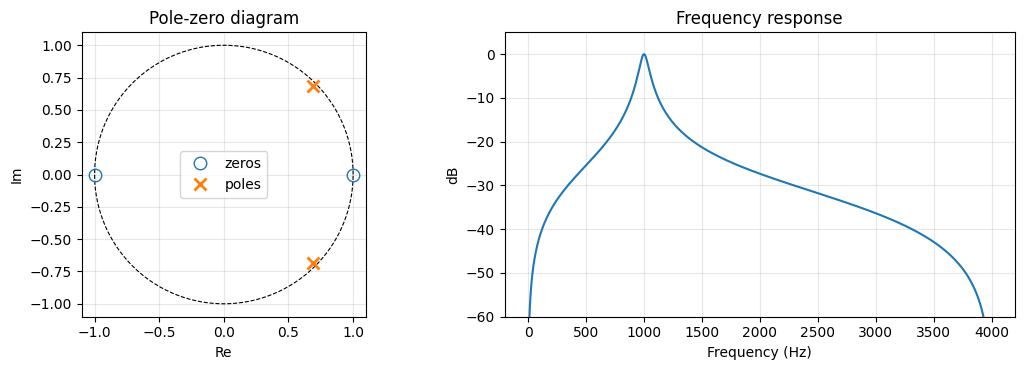

peak at 1000 Hz, -3 dB bandwidth ≈ 76 Hz (theory ≈ 2(1-r)fs/(2π) = 76 Hz)


In [6]:
fs, f0, r = 8000, 1000, 0.97
th0 = 2*np.pi*f0/fs                      # = pi/4
a = [1, -2*r*np.cos(th0), r**2]          # poles at r e^{±j th0}
b = [1, 0, -1]                           # zeros at z = +1 and z = -1  ->  1 - z^-2

# normalise to 0 dB gain at the resonance
_, H0 = signal.freqz(b, a, worN=[th0])
b = np.array(b) / np.abs(H0[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
zplane(b, a, ax1); ax1.set_title("Pole-zero diagram")
f, H = signal.freqz(b, a, worN=2048, fs=fs)
ax2.plot(f, 20*np.log10(np.abs(H) + 1e-12)); ax2.set_ylim(-60, 5)
ax2.set_xlabel("Frequency (Hz)"); ax2.set_ylabel("dB"); ax2.grid(alpha=0.3)
ax2.set_title("Frequency response")
plt.tight_layout(); plt.show()

# -3 dB bandwidth
mag = 20*np.log10(np.abs(H) + 1e-12); idx = np.where(mag >= -3)[0]
print(f"peak at {f[np.argmax(mag)]:.0f} Hz, -3 dB bandwidth ≈ {f[idx[-1]] - f[idx[0]]:.0f} Hz "
      f"(theory ≈ 2(1-r)fs/(2π) = {2*(1-r)*fs/(2*np.pi):.0f} Hz)")

np.random.seed(0)
x = np.random.randn(2*fs)
y = signal.lfilter(b, a, x)
y /= np.max(np.abs(y))
Audio(y, rate=fs)

**Observation (4.5):** a(z) = 1 − 2(0.97)cos(π/4)z⁻¹ + 0.97²z⁻² puts poles at 0.97·e^{±jπ/4}, so the response peaks at 1 kHz (= fs/8). The zeros at z = ±1 force exact nulls at 0 Hz and 4 kHz. The output of white noise sounds like a narrow-band tone/whistle around 1 kHz.

## Checkpoint 4
Stability classification: Task 4.4 table above. Resonator response: Task 4.5.

## Analysis questions
**1. Effect of r on bandwidth (Task 4.3).** The −3 dB bandwidth is approximately 2(1 − r) rad/sample, so as r → 1 the poles approach the unit circle, the peak gets taller and narrower (sharper resonance) and h(n) decays more slowly. For small r (0.5) the peak is broad and low and h(n) dies out in a few samples.

**2. Pole exactly on the unit circle.** The term rⁿ has r = 1, so h(n) neither decays nor grows – it is a sustained sinusoid (or constant for a pole at z = 1). The system is marginally stable: bounded impulse response but Σ|h(n)| = ∞, so it is not BIBO stable (a bounded input at the pole frequency gives an unbounded output), and |H| is infinite at that frequency.

**3. Zeros at z = ±1 → band-pass.** Zeros on the unit circle make |H| = 0 at ω = 0 (z = 1, blocks DC) and ω = π (z = −1, blocks fs/2). The pole pair gives a peak at ω = π/4 in between, so low and high frequencies are rejected and only the band around 1 kHz passes → band-pass.

**4. Stability triangle (A(z) = 1 + a₁z⁻¹ + a₂z⁻²; stable iff |a₂| < 1 and |a₁| < 1 + a₂).**
- (a) a₁ = −1.6, a₂ = 0.89: |a₂| = 0.89 < 1 ✓; |a₁| = 1.6 < 1.89 ✓ → **stable**.
- (b) a₁ = −2.5, a₂ = 1: |a₂| = 1 is not < 1 ✗ → **unstable**.
- (c) a₁ = 0.5, a₂ = −0.5: |a₂| < 1 ✓; |a₁| = 0.5 < 1 + (−0.5) = 0.5? No (equal) → on the boundary → **marginally stable** (pole at z = −1).

All three agree with the pole locations found in Task 4.4.

## AI-use statement
I used an AI assistant (Claude) to help generate and check the code structure of this notebook. I ran the code, checked the results against the pre-lab hand calculations, and wrote/verified the observations and answers myself.